# M4 - Conduction and thermal analysis

**Tutoring track, 057922 Nuclear Design and Technology** · Politecnico di Milano

Author: Giovanni Zullo

Run the cells in order, or **Runtime > Run all**.

---

## Contents

1. Fourier's law and the heat diffusion equation
2. The plane wall without a source
3. Resistances in series, and the overall coefficient $U$
4. Cylindrical geometry, and when the slab approximation is good enough
5. A volumetric source
6. Checking your own answer
7. When $k$ depends on temperature: the conductivity integral
8. Exercises


---
## 1. Fourier's law and the heat diffusion equation

Fourier's law states that heat flows down the temperature gradient,

$$\mathbf{q}'' = -k \, \nabla T,$$

with $\mathbf{q}''$ the heat flux (W/m$^2$) and $k$ the thermal conductivity
(W/(m K)). Combining it with an energy balance on a control volume that
generates heat at a volumetric rate $q'''$ (W/m$^3$) gives, at steady state,

$$\nabla \cdot (k \nabla T) + q''' = 0.$$

For constant $k$ and one-dimensional geometries this reduces to

$$\text{plane wall:}\quad \frac{d^2T}{dx^2} = -\frac{q'''}{k},
\qquad
\text{cylinder:}\quad \frac{1}{r}\frac{d}{dr}\left(r\frac{dT}{dr}\right) = -\frac{q'''}{k}.$$

Sections 2 to 6 solve one of these two equations with different right-hand sides and
boundary conditions; section 7 reduces a temperature-dependent $k$ to them.

### Boundary conditions

| Type | Physical meaning | Form |
|---|---|---|
| Dirichlet | imposed surface temperature | $T = T_s$ |
| Neumann | imposed flux (adiabatic if zero) | $-k\,dT/dn = q''_s$ |
| Robin | convection to a fluid at $T_f$ | $-k\,dT/dn = h\,(T_s - T_f)$ |

The Robin condition is the physically honest one for a wall cooled by a fluid: it does
not pretend to know the surface temperature, it couples it to the flow through $h$.
Here $h$ is taken as given.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (7, 4.2), 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})

# ---- neutral material and geometry, used throughout ----
k_steel = 20.0      # W/(m K)   thermal conductivity
t_wall  = 0.10      # m         wall thickness
print(f'steel wall: k = {k_steel} W/(m K), t = {t_wall*1000:.0f} mm')


steel wall: k = 20.0 W/(m K), t = 100 mm


---
## 2. The plane wall without a source

With $q''' = 0$ the equation is $d^2T/dx^2 = 0$: the profile is **a straight line**,
whatever the boundary conditions. The flux is then uniform through the thickness,

$$q'' = k\,\frac{T_1 - T_2}{t},$$

which is usually written as a **thermal resistance** (per unit area)

$$R_{\text{cond}} = \frac{t}{k}, \qquad q'' = \frac{\Delta T}{R}.$$

The analogy with Ohm's law is exact and worth internalising: temperature difference
plays the role of voltage, flux of current, and resistances in series add.


R_cond = t/k = 0.0050 m2 K/W
q'' = 50.00 kW/m2  (uniform through the wall)


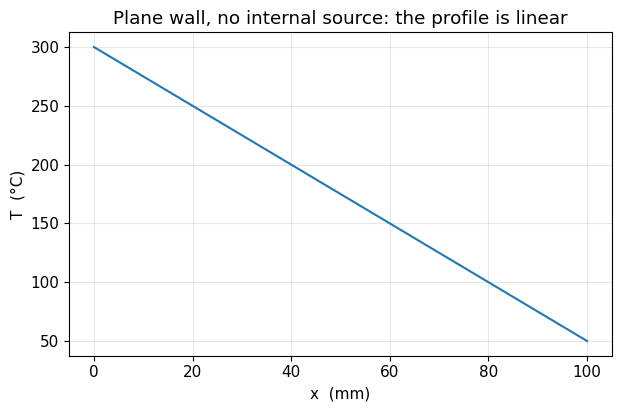

In [2]:
T1, T2 = 300.0, 50.0          # °C, the two surface temperatures

x = np.linspace(0, t_wall, 200)
T_lin = T1 + (T2 - T1) * x / t_wall
q_flux = k_steel * (T1 - T2) / t_wall

print(f'R_cond = t/k = {t_wall/k_steel:.4f} m2 K/W')
print(f"q'' = {q_flux/1000:.2f} kW/m2  (uniform through the wall)")

plt.plot(x*1000, T_lin)
plt.xlabel('x  (mm)'); plt.ylabel('T  (°C)')
plt.title('Plane wall, no internal source: the profile is linear')
plt.show()


---
## 3. Resistances in series, and the overall coefficient $U$

A real wall is rarely alone. Consider, from inside out: a convective film $h_1$, the
steel wall, an insulating layer, and an outer film $h_2$. In series,

$$R_{\text{tot}} = \underbrace{\frac{1}{h_1}}_{\text{inner film}}
+ \underbrace{\frac{t}{k}}_{\text{steel}}
+ \underbrace{\frac{t_{\text{ins}}}{k_{\text{ins}}}}_{\text{insulator}}
+ \underbrace{\frac{1}{h_2}}_{\text{outer film}},
\qquad U = \frac{1}{R_{\text{tot}}}.$$

### The subtlety worth remembering

In plane geometry every layer has the same area, so $U$ is unambiguous. **In
cylindrical geometry it is not**: each layer sits at a different radius and therefore
has a different area. A resistance must then be referred to a chosen reference surface,

$$\frac{1}{U_{\text{ref}} A_{\text{ref}}} = \sum_i \frac{1}{U_i A_i}
\;\Longrightarrow\;
U_{\text{ref}} = \left[\sum_i \frac{A_{\text{ref}}}{A_i}\,R_i\right]^{-1}, \qquad R_i = 1/U_i.$$

A value of $U$ without a stated reference surface is meaningless. When you report one,
**say which surface it refers to** - a large fraction of the errors in this kind of
calculation come from silently mixing references.

The cell below shows how much it matters. It also prints what doubling the steel thickness, or the outer coefficient $h_2$,
does to the heat flow: the share of each resistance predicts both.


![The same four-layer wall drawn twice: as a plane wall, where every layer has the same area and the temperature drops in proportion to each resistance, and as a cylindrical wall, where each layer sits at a different radius and therefore has a different area.](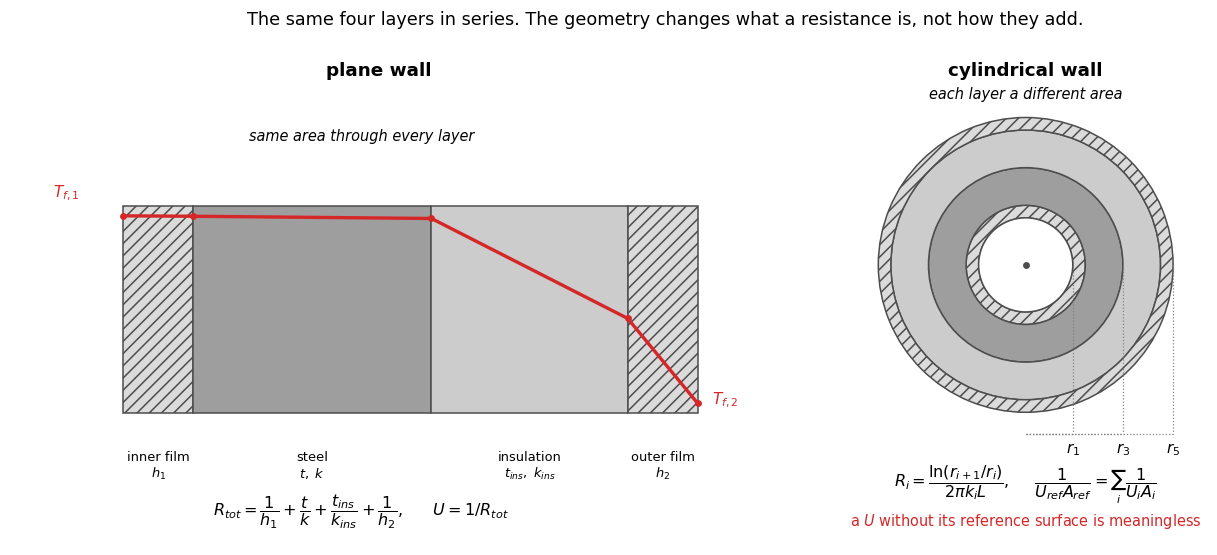)

*The same four layers, in two geometries. In the plane wall every layer has the same area, so the resistances add as $t/k$ and $U$ needs no further qualification; the red profile drops across each layer in proportion to its resistance, which is why almost all of the drop happens in the insulation and the outer film. In the cylinder the area grows with radius: the resistance gains a logarithm and $U$ is meaningless until you name the surface it refers to. Drawn by `figures/make_figures.py`.*


In [3]:
h1     = 5000.0     # W/(m2 K)  inner convective film
h2     = 25.0       # W/(m2 K)  outer natural convection
t_ins, k_ins = 0.04, 0.85       # m, W/(m K)   insulating layer

R_in, R_steel, R_insul, R_out = 1/h1, t_wall/k_steel, t_ins/k_ins, 1/h2
R_tot = R_in + R_steel + R_insul + R_out

print('resistances (m2 K/W) and share of the total')
for name, R in [('inner film', R_in), ('steel', R_steel),
                ('insulator', R_insul), ('outer film', R_out)]:
    print(f'  {name:12s} {R:8.5f}   {100*R/R_tot:5.1f} %')
print(f'  {"TOTAL":12s} {R_tot:8.5f}')
print(f'\nU (plane) = {1/R_tot:.2f} W/(m2 K)')
print(f'doubling the steel thickness: heat flow {100*(R_tot/(R_tot + R_steel) - 1):+.1f} %')
print(f'doubling h2 (outer film):     heat flow {100*(R_tot/(R_tot - R_out/2) - 1):+.1f} %')

# --- the same stack in cylindrical geometry, referred to two different surfaces ---
R_i = 0.60                       # m, inner radius of the steel wall
R_o = R_i + t_wall               # m, outer radius of the steel
R_x = R_o + t_ins                # m, outside of the insulator

# per unit length: R'_cond = ln(r2/r1)/(2 pi k),  R'_conv = 1/(2 pi r h)
Rp = (1/(2*np.pi*R_i*h1) + np.log(R_o/R_i)/(2*np.pi*k_steel)
      + np.log(R_x/R_o)/(2*np.pi*k_ins) + 1/(2*np.pi*R_x*h2))

U_ref_inner = 1/(Rp * 2*np.pi*R_i)   # referred to the INNER steel surface
U_ref_outer = 1/(Rp * 2*np.pi*R_o)   # referred to the OUTER steel surface
print(f'U referred to r = R_i ({R_i:.2f} m): {U_ref_inner:.2f} W/(m2 K)')
print(f'U referred to r = R_o ({R_o:.2f} m): {U_ref_outer:.2f} W/(m2 K)')
print(f'ratio = {U_ref_inner/U_ref_outer:.3f}  -> the SAME wall, two legitimate numbers')


resistances (m2 K/W) and share of the total
  inner film    0.00020     0.2 %
  steel         0.00500     5.4 %
  insulator     0.04706    51.0 %
  outer film    0.04000    43.4 %
  TOTAL         0.09226

U (plane) = 10.84 W/(m2 K)
doubling the steel thickness: heat flow -5.1 %
doubling h2 (outer film):     heat flow +27.7 %
U referred to r = R_i (0.60 m): 13.07 W/(m2 K)
U referred to r = R_o (0.70 m): 11.21 W/(m2 K)
ratio = 1.167  -> the SAME wall, two legitimate numbers


---
## 4. Cylindrical geometry, and when the slab approximation is good enough

In a cylinder without a source the profile is **logarithmic**, not linear:

$$T(r) = T_i - \frac{q'}{2\pi k}\,\ln\!\frac{r}{R_i},$$

with $q'$ the power per unit length and $T_i$ the temperature at the inner radius $R_i$. The physical reason is simple: the same power
crosses an area that grows with $r$, so the flux - and therefore the slope - decreases
outward.

A **slab approximation** for a cylindrical wall is a legitimate engineering move, but you should be able to say *how good it is*
rather than take it on faith. The relevant parameter is the thickness-to-radius ratio
$t/R_i$: the thinner the wall relative to its radius, the flatter the curvature and the
better the straight line.

The cell below quantifies the error instead of asserting it.


In [4]:
def slab_vs_cylinder(t_over_Ri, Ri=0.60, k=k_steel, dT=100.0):
    """Max |T_cyl - T_slab| across the wall, for the same inner flux and T(R_i)."""
    t  = t_over_Ri * Ri
    Ro = Ri + t
    qi = k * dT / t                 # inner-surface flux giving dT across a slab
    Qp = qi * 2*np.pi*Ri            # same power per unit length
    r  = np.linspace(Ri, Ro, 400)
    T_cyl  = -Qp/(2*np.pi*k) * np.log(r/Ri)
    T_slab = -qi/k * (r - Ri)
    return np.abs(T_cyl - T_slab).max(), dT

print(' t/Ri     max |T_cyl - T_slab|     relative to the wall ΔT')
for ratio in [0.02, 0.05, 0.10, 0.17, 0.25, 0.50]:
    err, dT = slab_vs_cylinder(ratio)
    print(f' {ratio:4.2f}      {err:7.2f}°C              {100*err/dT:5.1f} %')

print('\nRule of thumb: below t/Ri ~ 0.1 the slab approximation costs a few per cent.')
print('Above that, state the approximation explicitly and estimate its cost.')


 t/Ri     max |T_cyl - T_slab|     relative to the wall ΔT
 0.02         0.99°C                1.0 %
 0.05         2.42°C                2.4 %
 0.10         4.69°C                4.7 %
 0.17         7.64°C                7.6 %
 0.25        10.74°C               10.7 %
 0.50        18.91°C               18.9 %

Rule of thumb: below t/Ri ~ 0.1 the slab approximation costs a few per cent.
Above that, state the approximation explicitly and estimate its cost.


---
## 5. A volumetric source

### 5a. Uniform source

With $q''' = $ const the plane-wall equation integrates to a **parabola**:

$$T(x) = -\frac{q'''}{2k}x^2 + C_1 x + C_2 .$$

### 5b. Exponentially attenuated source - the case that matters here

Gamma radiation entering a wall is absorbed progressively, so the source is not
uniform. To a good approximation it decays exponentially,

$$q'''(x) = q'''_0\,e^{-\mu x},$$

where $\mu$ (m$^{-1}$) is an effective attenuation coefficient and $1/\mu$ is
the depth over which most of the energy is deposited. The equation

$$\frac{d^2T}{dx^2} = -\frac{q'''_0}{k}e^{-\mu x}$$

integrates twice to

$$\boxed{\;T(x) = -\frac{q'''_0}{k\mu^{2}}e^{-\mu x} + C_1 x + C_2\;}$$

and the flux follows from Fourier:

$$q''(x) = -k\frac{dT}{dx} = -kC_1 - \frac{q'''_0}{\mu}e^{-\mu x}.$$

$C_1$ and $C_2$ come from the two boundary conditions. With convection on both faces
(fluid at $T_{f,1}$ with $h_1$ inside, at $T_{f,2}$ with $U_2$ outside) they satisfy

$$h_1\big(T_{f,1} - T(0)\big) = q''(0), \qquad U_2\big(T(t) - T_{f,2}\big) = q''(t),$$

a $2\times 2$ linear system. Note the **sign convention**: both express "flux entering
the wall at $x=0$" and "flux leaving it at $x=t$", both positive in the $+x$ direction.
Getting these two signs consistent is where most of the difficulty lies; the algebra
afterwards is mechanical.


In [5]:
def solve_wall(k, t, mu, q0, h1, T1, U2, T2):
    """Steady plane wall with source q0*exp(-mu x), convection on both faces.
    Returns T(x), dT/dx(x) and flux(x) as callables."""
    a  = q0 / (k * mu**2)          # amplitude of the exponential part
    Et = np.exp(-mu * t)
    # Inner BC:  k C1 - h1 C2            = -h1 T1 - h1 a - q0/mu
    # Outer BC:  (U2 t + k) C1 + U2 C2   =  U2 a Et + U2 T2 - q0 Et/mu
    M = np.array([[k,          -h1],
                  [U2*t + k,    U2]])
    rhs = np.array([-h1*T1 - h1*a - q0/mu,
                     U2*a*Et + U2*T2 - q0*Et/mu])
    C1, C2 = np.linalg.solve(M, rhs)
    T    = lambda x: -a*np.exp(-mu*x) + C1*x + C2
    dTdx = lambda x:  a*mu*np.exp(-mu*x) + C1
    flux = lambda x: -k*dTdx(x)
    return T, dTdx, flux, (C1, C2)

# ---- neutral case ----
mu   = 25.0        # 1/m      attenuation coefficient  -> 1/mu = 40 mm
q0   = 2.0e6       # W/m3     source at the inner surface
T_in, T_out = 300.0, 50.0     # °C  bulk fluid temperatures
U2   = 50.0        # W/(m2 K) outer overall coefficient

T, dTdx, flux, (C1, C2) = solve_wall(k_steel, t_wall, mu, q0, h1, T_in, U2, T_out)

xs = np.linspace(0, t_wall, 2001)
i_max = np.argmax(T(xs))
print(f'T(0)   = {T(0):7.2f}°C   (inner fluid is at {T_in}°C)')
print(f'T(t)   = {T(t_wall):7.2f}°C')
print(f'T_max  = {T(xs)[i_max]:7.2f}°C  at x = {xs[i_max]*1000:.1f} mm')
print(f'\n1/mu = {1000/mu:.1f} mm, i.e. most of the energy lands in the first'
      f' {100/mu/t_wall:.0f}% of the thickness')


T(0)   =  311.68°C   (inner fluid is at 300.0°C)
T(t)   =  350.57°C
T_max  =  371.93°C  at x = 52.4 mm

1/mu = 40.0 mm, i.e. most of the energy lands in the first 40% of the thickness


Look at the first number: **the wall is hotter than the fluid that cools it**.
That is not a mistake. The wall is generating heat internally, so it sheds heat to the
coolant on the inside *and* to the environment on the outside - the maximum sits
somewhere inside the thickness, not on a face.

That is why the peak temperature has to be *located*, not just bounded by the surface values.


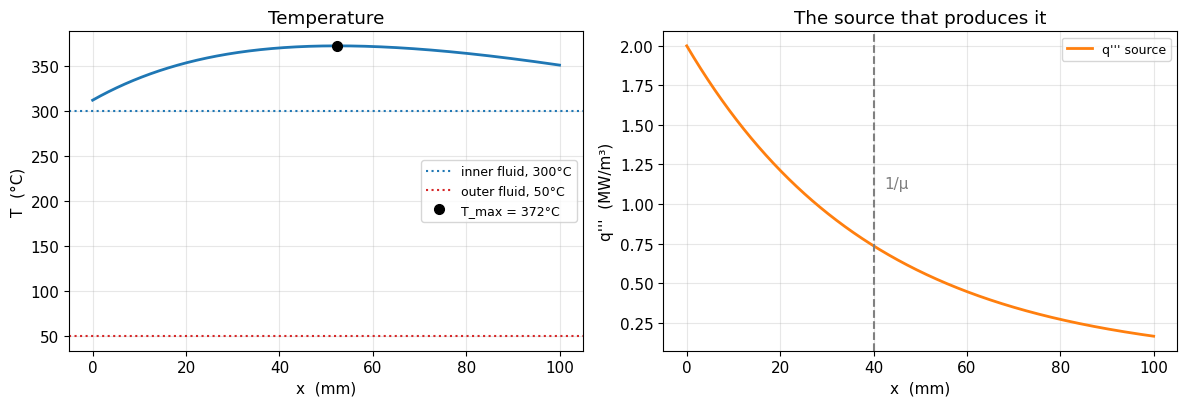

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].plot(xs*1000, T(xs), lw=2)
ax[0].axhline(T_in,  ls=':', c='C0', label=f'inner fluid, {T_in:.0f}°C')
ax[0].axhline(T_out, ls=':', c='C3', label=f'outer fluid, {T_out:.0f}°C')
ax[0].plot(xs[i_max]*1000, T(xs)[i_max], 'ko', ms=7,
           label=f'T_max = {T(xs)[i_max]:.0f}°C')
ax[0].set_xlabel('x  (mm)'); ax[0].set_ylabel('T  (°C)')
ax[0].set_title('Temperature'); ax[0].legend(fontsize=9)

ax[1].plot(xs*1000, q0*np.exp(-mu*xs)/1e6, lw=2, c='C1', label="q''' source")
ax[1].set_xlabel('x  (mm)'); ax[1].set_ylabel("q'''  (MW/m³)")
ax[1].set_title('The source that produces it'); ax[1].legend(fontsize=9)
ax[1].axvline(1000/mu, ls='--', c='grey')
ax[1].text(1000/mu*1.06, q0/1e6*0.55, '1/μ', color='grey')

plt.tight_layout()
import os
# Export for the course notes. The target is named by an environment variable
# that only the author sets, so this is a no-op everywhere else: without the
# guard the cell would raise FileNotFoundError for every student.
_cn = os.environ.get("NDT_COURSE_NOTES_FIGURES", "")
if os.path.isdir(_cn):
    plt.savefig(os.path.join(_cn, "04_attenuated_source.pdf"), bbox_inches="tight")
plt.show()


---
## 6. Checking your own answer

This is the habit the course is really trying to build. An analytical result is not
trustworthy because it came out of an integration - it is trustworthy because it
survives checks that would have caught a mistake. Three cheap ones, in increasing
order of strength:

1. **Do the boundary conditions hold?** Substitute the solution back in. This catches
   sign and algebra errors in $C_1$, $C_2$.
2. **Does energy balance?** Everything generated inside must leave through the two
   faces: $\int_0^t q'''\,dx = q''(t) - q''(0)$. This catches a wrong source term.
3. **Does an independent method agree?** Solve the same problem by finite differences
   and compare. This catches errors the first two miss, because nothing is shared
   between the two solutions except the physics.

Check 3 is the small-scale version of what you will do later with z3st: hand
calculation first, field solution second, then ask why they differ.


In [7]:
# --- check 1: boundary conditions ---
r_in  = h1*(T_in - T(0)) - flux(0)
r_out = U2*(T(t_wall) - T_out) - flux(t_wall)
print(f'BC residual, inner face : {r_in:+.3e} W/m2')
print(f'BC residual, outer face : {r_out:+.3e} W/m2')

# --- check 2: global energy balance ---
generated = q0/mu * (1 - np.exp(-mu*t_wall))       # integral of the source
net_out   = flux(t_wall) - flux(0)
print(f'\ngenerated  = {generated/1000:8.2f} kW/m2')
print(f'net leaving = {net_out/1000:8.2f} kW/m2')
print(f'imbalance   = {abs(generated-net_out):.3e} W/m2')


BC residual, inner face : -1.819e-10 W/m2
BC residual, outer face : -1.819e-12 W/m2

generated  =    73.43 kW/m2
net leaving =    73.43 kW/m2
imbalance   = 0.000e+00 W/m2


max |analytical - finite difference| = 2.49e-02°C
PASS


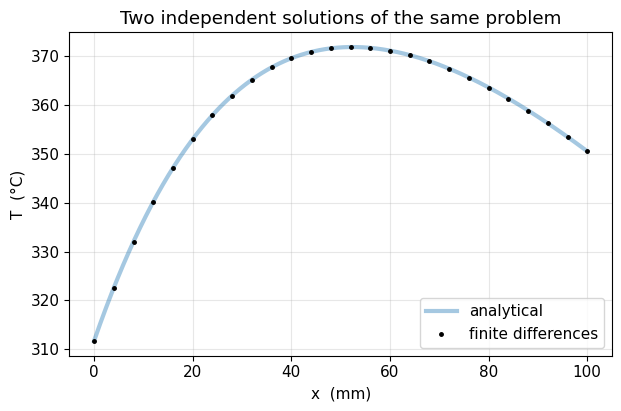

In [8]:
# --- check 3: an independent finite-difference solution ---
def wall_finite_difference(n=2001):
    xg = np.linspace(0, t_wall, n); dx = xg[1] - xg[0]
    M  = np.zeros((n, n)); b = np.zeros(n)
    for i in range(1, n-1):                       # interior: T'' = -q'''/k
        M[i, i-1:i+2] = [1.0, -2.0, 1.0]
        b[i] = -q0*np.exp(-mu*xg[i]) * dx**2 / k_steel
    M[0, 0], M[0, 1], b[0]     = -(k_steel/dx + h1), k_steel/dx, -h1*T_in
    M[-1, -1], M[-1, -2], b[-1] = -(k_steel/dx + U2), k_steel/dx, -U2*T_out
    return xg, np.linalg.solve(M, b)

xg, T_fd = wall_finite_difference()
err = np.abs(T_fd - T(xg)).max()
print(f'max |analytical - finite difference| = {err:.2e}°C')
print('PASS' if err < 0.05 else 'FAIL: investigate before trusting either solution')

plt.plot(xg*1000, T(xg), lw=3, alpha=0.4, label='analytical')
plt.plot(xg[::80]*1000, T_fd[::80], 'k.', ms=5, label='finite differences')
plt.xlabel('x  (mm)'); plt.ylabel('T  (°C)')
plt.title('Two independent solutions of the same problem')
plt.legend(); plt.show()


---
## 7. When $k$ depends on temperature: the conductivity integral

Across a few hundred degrees the conductivity of steel is not constant, and in nuclear
fuel it varies enormously. Then $k$ cannot come out of the derivative, and
$\nabla\cdot(k\nabla T) = -q'''$ is nonlinear in $T$.

The classical device is to change variable to the **conductivity integral**

$$\Theta(T) = \int_{T_{\text{ref}}}^{T} k(T')\,dT' ,$$

because $k\nabla T = \nabla\Theta$. The equation becomes linear in $\Theta$,
$\nabla^2\Theta = -q'''$, and is solved as before - then $T$ is recovered by inverting
$\Theta$. The practical consequence is that tabulated $\int k\,dT$ values, rather than
$k$ itself, are what you actually need; this is why fuel-performance handbooks tabulate
the integral.

The cell below shows the size of the error you make by ignoring the variation.


k(300°C) = 20.00,  k(600°C) = 17.60 W/(m K)
conductivity integral  =   5640.0 W/m
equivalent constant k  =    18.80 W/(m K)
using k at the cold end:   6000.0 W/m  -> +6.4 % error on the flux


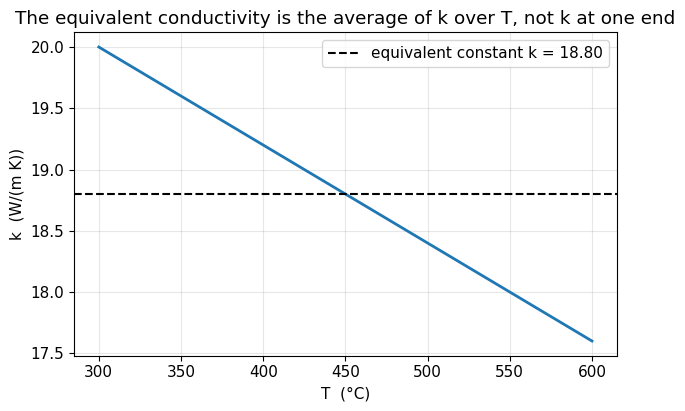

In [9]:
# a mildly temperature-dependent conductivity (neutral, illustrative)
k_of_T = lambda T_: 20.0 - 0.008*(T_ - 300.0)     # W/(m K)

T_lo, T_hi = 300.0, 600.0
Tg = np.linspace(T_lo, T_hi, 2001)

Theta   = np.trapezoid(k_of_T(Tg), Tg)            # exact: integral of k dT
k_avg  = Theta / (T_hi - T_lo)                   # the correct 'average' k
naive   = k_of_T(T_lo) * (T_hi - T_lo)            # using k at the cold end

print(f'k({T_lo:.0f}°C) = {k_of_T(T_lo):.2f},  k({T_hi:.0f}°C) = {k_of_T(T_hi):.2f} W/(m K)')
print(f'conductivity integral  = {Theta:8.1f} W/m')
print(f'equivalent constant k  = {k_avg:8.2f} W/(m K)')
print(f'using k at the cold end: {naive:8.1f} W/m  ->'
      f' {100*(naive-Theta)/Theta:+.1f} % error on the flux')

plt.plot(Tg, k_of_T(Tg), lw=2)
plt.axhline(k_avg, ls='--', c='k', label=f'equivalent constant k = {k_avg:.2f}')
plt.xlabel('T  (°C)'); plt.ylabel('k  (W/(m K))')
plt.title('The equivalent conductivity is the average of k over T, not k at one end')
plt.legend(); plt.show()


---
## 8. Exercises

Do these by hand first; use the notebook code cells only to check.

**E1 - Adiabatic outer face.** Redo §5b with the outer face insulated instead of
cooled ($q''(t) = 0$). Show that
$C_1 = -\dfrac{q'''_0}{k\mu}e^{-\mu t}$, and that the temperature then increases
monotonically across the wall, so the maximum sits **on the outer face**. Explain
physically why the peak moved there.

**E2 - Thin-wall limit.** Show that for $\mu t \ll 1$ the exponential source tends to a
uniform one, and that the solution of §5b tends to the parabola of §5a. What does
$\mu t \ll 1$ mean physically about where the radiation is absorbed?

**E3 - Where is the peak?** From $dT/dx = 0$, derive a closed-form expression for the
position $x_{\max}$ of the maximum in the two-sided convective case, and verify it
against the numerical value printed in §5b. Under what condition does no interior
maximum exist?

**E4 - Reference surface.** A cylindrical wall has $R_i = 0.5$ m and $t = 0.12$ m, and
carries the inner film, insulator and outer film of §3. Compute $U$ referred to the inner surface and
to the outer one, and show explicitly that the two give the *same* heat loss per unit
length. Which would you report, and why?

**E5 - Judging the approximation.** For $t/R_i = 0.3$, estimate the error committed
by the slab approximation, and state it as a sentence you would be willing to put in a
technical report - i.e., with a number and a direction, not just "small".
